<a href="https://colab.research.google.com/github/xErnyx/Practica_2_Preprocesamiento_de_Datos/blob/main/Practica_2_Preprocesamiento_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Practica N°2: Preprocesamiento de Datos**
---
Juan D. Figueroa

Universidad Salesiana del Ecuador - Sede sur

Inteligencia Artificial

Ciencias de la computación

Ing. Rodrigo Tufiño

16 de octubre del 2026

# **📌 Introducción**
---
Antes de entrenar un modelo de inteligencia artificial, los datos deben entenderse y prepararse: hay que saber qué representa cada fila y cada columna, de qué tipo es cada variable y en qué escala está medida.

El trabajo se organiza en cuatro fases. La Fase 1 analiza la anatomía de un dataset (instancias, atributos, features, label y tipos de variables). La Fase 2 implementa desde cero con NumPy las transformaciones Min-Max y Z-Score. La Fase 3 aplica lo aprendido a un dataset real, Palmer Penguins (Gorman et al., 2014), con pandas. La Fase 4 reproduce los resultados con scikit-learn (Pedregosa et al., 2011) y añade el RobustScaler y la división train/test. Cada fase presenta el fundamento teórico, el código paso a paso y las respuestas a las preguntas de la guía.

# **🎯 Objetivos**
---
**Objetivo general**

Aplicar técnicas de preprocesamiento de datos (identificación de variables y escalado) sobre datasets reales, interpretando el efecto de cada transformación en el contexto del problema.

**Objetivos específicos**

1.   Identificar instancias, atributos, features y labels en un dataset real.
2.   Clasificar variables según su tipo (cuantitativa/cualitativa, discreta/continua, nominal/ordinal).
3.   Aplicar e interpretar las transformaciones Min-Max, Z-Score y Robust Scaler.
4.   Argumentar cuándo y por qué usar cada técnica de escalado según el contexto del dataset.
5.   Probar diferentes librerías (NumPy, pandas y scikit-learn) para transformar variables.

# **🛠️ Verificación del entorno**
---
Antes de empezar se comprueba que las librerías necesarias estén disponibles. En Colab ya vienen instaladas, por lo que solo se importan. La convención `as np`, `as pd` y `as plt` es universal en el ecosistema científico de Python.

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print("✅ Todas las librerías cargadas correctamente")

✅ Todas las librerías cargadas correctamente


# **📐 Fase 1 Anatomía de un Dataset**
---
**Fundamento teórico**

1.   Dataset: conjunto de datos organizado en una tabla.
2.   Instancia: cada fila; representa una observación individual (una persona, un objeto, un evento).
3.   Atributo: cada columna; describe una característica de la instancia.
4.   Feature: atributo que se usa como entrada del modelo para predecir.
5.   Label: atributo que se quiere predecir (la salida). En aprendizaje supervisado cada instancia trae su label.
6.   Tipos de variable: **cuantitativa** (numérica) o **cualitativa** (categórica). Las cuantitativas pueden ser **discretas** (se cuentan, valores aislados) o **continuas** (se miden, cualquier valor en un rango). Las cualitativas pueden ser **nominales** (categorías sin orden) u **ordinales** (categorías con un orden natural).

# 1. Cargar el dataset de estudiantes
---
Se ejecuta el bloque tal como lo entrega la guía, sin modificar nada. Se construye un diccionario (columna → lista de valores) y `pd.DataFrame` lo convierte en tabla. La guía imprime dos veces `df`; aquí se deja una sola impresión.

In [2]:
import numpy as np
import pandas as pd

datos = {
    "nombre":        ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad":          [21,    23,     20,      25,       22,      21],
    "promedio_gpa":  [8.9,   7.4,    9.5,     6.1,      8.2,     7.8],
    "horas_estudio": [18,    10,     22,      6,        15,      12],
    "distancia_km":  [2.5,   15.0,   0.8,     40.2,     5.1,     8.7],
    "carrera": [
        "Computación","Computación","Redes","Redes","Computación","Redes"],
    "nivel_ingles": [
        "Básico", "Intermedio","Avanzado","Básico","Avanzado","Intermedio"],
    "beca":          [1,     0,      1,       0,        1,       0],
    "aprobado":      ["Sí",  "No",   "Sí",    "No",     "Sí",    "No"]
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)


# 2. Actividad 1.1: Identifica la estructura
---

*P1. ¿Cuántas instancias (filas) tiene este dataset? ¿Qué representa cada instancia en el mundo real?*

In [4]:
# df.shape devuelve una TUPLA (filas, columnas)
print(df.shape)
print(f"Instancias (filas):   {df.shape[0]}")
print(f"Atributos (columnas): {df.shape[1]}")

(6, 9)
Instancias (filas):   6
Atributos (columnas): 9


**Respuesta:** El dataset tiene **6 instancias** (filas) y 9 columnas. Cada instancia representa **un estudiante real** (Ana, Luis, María, Carlos, Sofía y Diego), descrito por sus datos académicos y personales.

*P2. Lista todos los atributos (columnas). Ahora sepáralos en dos grupos: ¿cuáles actuarían como features y cuál sería el label si tu objetivo fuera predecir si un estudiante aprueba o no?*

In [6]:
atributos = list(df.columns)
print("Atributos:", atributos)

# El label es la columna que queremos predecir
label = "aprobado"
# Features: todo lo demás, excepto el label y el identificador 'nombre' (ver P3)
features = [c for c in atributos if c not in (label, "nombre")]

print("\nLabel   :", label)
print("Features:", features)

# En ML se separa en X (entradas) e y (salida)
X_est = df[features]
y_est = df[label]
print(X_est.shape, y_est.shape)

Atributos: ['nombre', 'edad', 'promedio_gpa', 'horas_estudio', 'distancia_km', 'carrera', 'nivel_ingles', 'beca', 'aprobado']

Label   : aprobado
Features: ['edad', 'promedio_gpa', 'horas_estudio', 'distancia_km', 'carrera', 'nivel_ingles', 'beca']
(6, 7) (6,)


**Respuesta:** Los 9 atributos son `nombre`, `edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles`, `beca` y `aprobado`.

*   **Label:** `aprobado` (es lo que se quiere predecir; toma los valores "Sí" o "No").
*   **Features:** `edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles` y `beca` (7 en total). `nombre` queda fuera por la razón explicada en P3.

Observación: en estos 6 estudiantes, `promedio_gpa` separa perfectamente a los aprobados (8.2, 8.9 y 9.5) de los reprobados (6.1, 7.4 y 7.8). En un caso real habría que verificar que el GPA no se calcule a partir del propio resultado, porque entonces el modelo "haría trampa".

*P3. La columna nombre es un atributo, pero ¿debería ser un feature para un modelo de ML? ¿Por qué sí o por qué no?*

In [7]:
# ¿Cada nombre es único? Si lo es, funciona como identificador, no como característica
print("Nombres distintos:", df["nombre"].nunique(), "de", len(df))
print("¿Todos únicos?   :", df["nombre"].is_unique)

Nombres distintos: 6 de 6
¿Todos únicos?   : True


**Respuesta:** **No debería ser un feature.** Es un *identificador*: cada valor es único (6 nombres distintos en 6 filas), por lo que no describe ninguna característica que se repita entre estudiantes ni guarda relación causal con aprobar. Si se incluyera, el modelo podría memorizar "Ana → Sí" (sobreajuste) y no aprendería nada que sirva para estudiantes nuevos. Además, dejarlo evita usar datos personales innecesarios. Sirve para identificar filas, no para predecir.

# 3. Actividad 1.2: Clasifica las variables
---
Se completa la tabla de la guía reemplazando cada `"?"`. Para las variables cualitativas la columna `discreta_o_continua` no aplica (`NA`), igual que `nominal_u_ordinal` no aplica a las cuantitativas.

In [8]:
clasificacion = {
    "columna": ["edad", "promedio_gpa", "horas_estudio", "distancia_km",
                "carrera", "nivel_ingles", "beca", "aprobado"],
    "cuantitativa_o_cualitativa": ["Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa",
                                   "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"],
    "discreta_o_continua":        ["Discreta", "Continua", "Continua", "Continua",
                                   "NA", "NA", "NA", "NA"],
    "nominal_u_ordinal":          ["NA", "NA", "NA", "NA",
                                   "Nominal", "Ordinal", "Nominal", "Nominal"]
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Continua   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa                  NA   
5   nivel_ingles                Cualitativa                  NA   
6           beca                Cualitativa                  NA   
7       aprobado                Cualitativa                  NA   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


**Justificación de la tabla:**

*   `edad`: se cuenta en años enteros → cuantitativa discreta.
*   `promedio_gpa`, `horas_estudio`, `distancia_km`: son magnitudes medidas que pueden tomar valores decimales (7.85 de GPA, 12.5 horas, 8.7 km) → cuantitativas continuas. En `horas_estudio` los datos vienen enteros, pero la magnitud (tiempo) es continua.
*   `carrera`: categorías sin orden (Computación, Redes) → cualitativa nominal.
*   `nivel_ingles`: categorías con orden natural (Básico < Intermedio < Avanzado) → cualitativa ordinal.
*   `beca` y `aprobado`: dos categorías sin orden (con beca/sin beca, Sí/No) → cualitativas nominales (binarias).

*P4. nivel_ingles tiene los valores Básico, Intermedio y Avanzado. ¿Es nominal u ordinal? ¿En qué te basas para decidirlo? ¿Importa esa distinción a la hora de entrenar un modelo?*

In [9]:
# Se declara el orden explícitamente con una categoría ORDENADA de pandas
orden = ["Básico", "Intermedio", "Avanzado"]
nivel = pd.Categorical(df["nivel_ingles"], categories=orden, ordered=True)

print("Menor nivel :", nivel.min())
print("Mayor nivel :", nivel.max())
print("Códigos     :", nivel.codes)   # 0 = Básico, 1 = Intermedio, 2 = Avanzado

Menor nivel : Básico
Mayor nivel : Avanzado
Códigos     : [0 1 2 0 2 1]


**Respuesta:** Es **ordinal**. Me baso en que las categorías tienen un orden natural y significativo (Básico < Intermedio < Avanzado): un nivel Avanzado es "más" que uno Básico. Lo que no se puede asegurar es que la distancia entre niveles sea la misma.

**Sí importa para el modelo.** Si es ordinal, se puede codificar con números que respetan el orden (0, 1, 2), como hace `pd.Categorical`/`OrdinalEncoder`, y el modelo aprovecha esa información. Si se tratara como nominal (por ejemplo con one-hot), se perdería el orden; y si una variable realmente nominal (como `carrera`) se codificara 0, 1, 2, el modelo creería que existe un orden que no existe.

*P5. La columna beca solo contiene 0 y 1. ¿Es cuantitativa discreta o cualitativa nominal? Justifica tu respuesta. Pista: piensa en si tiene sentido calcular la media de esos valores.*

In [10]:
print(df["beca"].value_counts())
print("\nMedia de 'beca':", df["beca"].mean())

beca
1    3
0    3
Name: count, dtype: int64

Media de 'beca': 0.5


**Respuesta:** Es **cualitativa nominal (binaria)**. Los números 0 y 1 son solo *etiquetas* de dos categorías (sin beca / con beca); no miden una cantidad. La prueba de la media lo confirma: `df["beca"].mean()` da 0.5, pero "0.5 de beca" no existe; ese valor únicamente indica que la mitad de los estudiantes tiene beca (una proporción). En una variable cuantitativa la media sí tiene interpretación (por ejemplo, 22 años de edad promedio).

# 4. Actividad 1.3: Inspeccionando tipos de datos
---
`df.dtypes` muestra el tipo que pandas *infiere* para cada columna según los valores almacenados, y `df.describe()` resume solo las columnas numéricas (conteo, media, desviación, mínimo, cuartiles y máximo).

In [11]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


*P6. ¿Coinciden los tipos que detecta pandas (int64, object, float64) con tu clasificación teórica de la actividad 1.2? Señala al menos un caso donde no coincidan y explica por qué pandas puede estar "equivocado" desde la perspectiva conceptual.*

In [12]:
comparacion = pd.DataFrame({
    "columna":      df.columns,
    "tipo_pandas":  df.dtypes.astype(str).values,
    "tipo_teorico": ["Cualitativa (identificador)", "Cuantitativa discreta",
                     "Cuantitativa continua", "Cuantitativa continua", "Cuantitativa continua",
                     "Cualitativa nominal", "Cualitativa ordinal",
                     "Cualitativa nominal (binaria)", "Cualitativa nominal (binaria)"],
    "coincide":     ["Sí", "Sí", "Sí", "No", "Sí", "Sí", "Parcial", "No", "Sí"]
})
print(comparacion)

         columna tipo_pandas                   tipo_teorico coincide
0         nombre      object    Cualitativa (identificador)       Sí
1           edad       int64          Cuantitativa discreta       Sí
2   promedio_gpa     float64          Cuantitativa continua       Sí
3  horas_estudio       int64          Cuantitativa continua       No
4   distancia_km     float64          Cuantitativa continua       Sí
5        carrera      object            Cualitativa nominal       Sí
6   nivel_ingles      object            Cualitativa ordinal  Parcial
7           beca       int64  Cualitativa nominal (binaria)       No
8       aprobado      object  Cualitativa nominal (binaria)       Sí


**Respuesta:** **No coinciden del todo**, porque pandas solo mira cómo están *almacenados* los valores, no qué *significan*:

*   `beca` aparece como `int64` (numérica), pero conceptualmente es **cualitativa nominal**. Por eso `describe()` la incluye y calcula una media y desviación sin sentido.
*   `horas_estudio` aparece como `int64` (como si fuera discreta), pero conceptualmente es **continua**: solo se registró con valores enteros.
*   `nivel_ingles` aparece como `object` (texto), igual que `carrera`; pandas no sabe que el primero es ordinal y el segundo nominal.

Conclusión: el tipo técnico (`dtype`) y el tipo conceptual son cosas distintas, y el analista debe decidir el segundo.

*P7. Observa las estadísticas descriptivas. ¿Qué columna tiene mayor dispersión (std)? ¿Qué problema podría ocasionar esa diferencia de escala si alimentas este dataset directamente a un algoritmo como KNN?*

In [13]:
cols_cont = ["promedio_gpa", "horas_estudio", "distancia_km"]

# Desviación estándar de las columnas numéricas, de mayor a menor
print(df.select_dtypes(include="number").std().round(2).sort_values(ascending=False))

# KNN usa distancia euclidiana: ¿cuánto aporta cada feature a la distancia Ana ↔ Carlos?
ana    = df.loc[0, cols_cont].astype(float).values
carlos = df.loc[3, cols_cont].astype(float).values
aporte = (ana - carlos) ** 2                         # diferencia² por feature
print("\nAporte² a la distancia Ana-Carlos:", dict(zip(cols_cont, aporte.round(2).tolist())))
print("Porcentaje del total (%):          ", dict(zip(cols_cont, (aporte / aporte.sum() * 100).round(1).tolist())))

distancia_km     14.69
horas_estudio     5.74
edad              1.79
promedio_gpa      1.19
beca              0.55
dtype: float64

Aporte² a la distancia Ana-Carlos: {'promedio_gpa': 7.84, 'horas_estudio': 144.0, 'distancia_km': 1421.29}
Porcentaje del total (%):           {'promedio_gpa': 0.5, 'horas_estudio': 9.2, 'distancia_km': 90.3}


**Respuesta:** La columna con mayor dispersión es **`distancia_km`** (std ≈ 14.69), seguida de `horas_estudio` (≈ 5.74). Las menos dispersas son `promedio_gpa` (≈ 1.19) y `beca` (≈ 0.55).

**Problema con KNN:** KNN decide con la *distancia euclidiana*, que suma las diferencias al cuadrado de todas las features. Como `distancia_km` varía en decenas de unidades y `promedio_gpa` en décimas, la distancia queda dominada por los kilómetros: entre Ana y Carlos, `distancia_km` aporta cerca del **90 %** de la distancia y el GPA apenas el 0.5 %. El algoritmo trataría a las demás variables como casi irrelevantes solo por estar en una escala menor, no porque lo sean. La solución es llevar todas las features a una escala comparable (escalado).

# **📐 Fase 2 Escalado con NumPy**
---
**Fundamento teórico**

Las features suelen venir en escalas muy distintas (años, kilómetros, gramos). Los algoritmos basados en distancias (KNN, K-Means) o en gradientes (regresión, redes neuronales) se ven afectados por esas diferencias, por lo que se transforman las columnas a una escala comparable. Esta fase implementa las fórmulas desde cero con NumPy para entender exactamente qué hace cada una:

1.   **Min-Max:** `x' = (x - min) / (max - min)`. Lleva cada columna al rango [0, 1]. Depende solo de dos valores: el mínimo y el máximo.
2.   **Z-Score (estandarización):** `z = (x - media) / desviación_estándar`. Deja cada columna con media 0 y desviación estándar 1. Usa todos los datos de la columna.

En ambos casos la operación se aplica **por columna** (`axis=0`) y se ejecuta vectorizada gracias al broadcasting: una matriz de forma `(n, m)` operada con un vector de forma `(m,)`.

# 1. Actividad 2.1: Preparando los datos
---
Se extrae solo la parte numérica continua del DataFrame como un array de NumPy (`.values`) de tipo `float`. El resultado es una matriz de 6 filas (estudiantes) × 3 columnas (features).

In [14]:
# Extraemos SOLO las columnas numéricas continuas para esta fase
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape}  →  {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3)  →  6 instancias, 3 features


*P8. ¿Por qué excluimos edad y beca de esta matriz aunque también son numéricas? ¿Tiene sentido escalar la columna beca que solo contiene 0 y 1?*

**Respuesta:** Esta fase trabaja solo con variables **cuantitativas continuas** para ver el efecto de las escalas sin otros factores.

*   `beca` **no tiene sentido escalarla**: es una variable categórica codificada con 0 y 1. Con Min-Max quedaría igual (ya está en [0, 1]) y con Z-Score se convertiría en dos valores arbitrarios (-1 y 1) sin significado, perdiendo su interpretación de "sí/no".
*   `edad` sí podría escalarse en un proyecto real (es cuantitativa); aquí se excluye porque varía en un rango muy pequeño (20 a 25 años) y la guía quiere centrarse en las tres features con escalas realmente distintas.

# 2. Actividad 2.2: Normalización Min-Max
---
**Paso a paso:** (1) `X.min(axis=0)` y `X.max(axis=0)` calculan el mínimo y el máximo de cada columna (vectores de forma `(3,)`). (2) `X - X_min` resta a cada columna su mínimo (broadcasting `(6,3) - (3,)`). (3) Se divide entre el rango `X_max - X_min`. La función devuelve también `X_min` y `X_max` porque son los parámetros que habría que reutilizar para transformar datos nuevos.

In [15]:
def min_max_manual(X):
    """
    Normalización Min-Max: transforma cada columna al rango [0, 1]
    Fórmula: x' = (x - min) / (max - min)
    """
    X_min = X.min(axis=0)   # mínimo por columna
    X_max = X.max(axis=0)   # máximo por columna
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


*P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?*

In [16]:
# Verificación: el mínimo y el máximo de cada columna transformada
print("Mínimo por columna:", X_minmax.min(axis=0))
print("Máximo por columna:", X_minmax.max(axis=0))

# ¿Quién queda en 0.0 y quién en 1.0 en cada feature?
nombres = df["nombre"].values
for i, col in enumerate(columnas_numericas):
    print(f"{col:<14} → 0.0: {nombres[X_minmax[:, i].argmin()]:<7} 1.0: {nombres[X_minmax[:, i].argmax()]}")

Mínimo por columna: [0. 0. 0.]
Máximo por columna: [1. 1. 1.]
promedio_gpa   → 0.0: Carlos  1.0: María
horas_estudio  → 0.0: Carlos  1.0: María
distancia_km   → 0.0: María   1.0: Carlos


**Respuesta:** Después de Min-Max, cada columna queda en el rango **[0, 1]**: el mínimo es exactamente **0.0** y el máximo exactamente **1.0**. La verificación lo confirma (`[0. 0. 0.]` y `[1. 1. 1.]`).

*   **0.0** representa el **valor más pequeño observado** en esa columna (por ejemplo, Carlos en `promedio_gpa` y en `horas_estudio`, y María en `distancia_km`).
*   **1.0** representa el **valor más grande observado** (por ejemplo, María en GPA y horas de estudio, y Carlos en `distancia_km`).

Los demás valores indican qué proporción del camino entre el mínimo y el máximo ocupan.

*P10. Fíjate en la columna distancia_km. Carlos vive a 40.2 km, que es un valor extremo. Ahora imagina que llega un nuevo estudiante que vive a 80 km. Si agregas ese dato y vuelves a normalizar, ¿qué le pasará al valor transformado de todos los demás estudiantes? ¿Es eso un problema? ¿Por qué?*

In [17]:
# Se agrega un estudiante nuevo (gpa=8.5, horas=14, distancia=80 km) y se vuelve a normalizar
X_80 = np.vstack([X, [8.5, 14, 80.0]])
X_80_mm, _, _ = min_max_manual(X_80)

comparacion = pd.DataFrame({
    "estudiante":          list(nombres) + ["Nuevo"],
    "distancia_km":        X_80[:, 2],
    "minmax_antes":        list(X_minmax[:, 2].round(4)) + [np.nan],
    "minmax_con_80km":     X_80_mm[:, 2].round(4)
})
print(comparacion)

  estudiante  distancia_km  minmax_antes  minmax_con_80km
0        Ana           2.5        0.0431           0.0215
1       Luis          15.0        0.3604           0.1793
2      María           0.8        0.0000           0.0000
3     Carlos          40.2        1.0000           0.4975
4      Sofía           5.1        0.1091           0.0543
5      Diego           8.7        0.2005           0.0997
6      Nuevo          80.0           NaN           1.0000


**Respuesta:** El máximo de `distancia_km` pasa de 40.2 a 80 km, así que **todos los valores transformados se comprimen hacia 0**. Por ejemplo, Carlos baja de 1.0000 a 0.4975, Luis de 0.3604 a 0.1793 y Diego de 0.2005 a 0.0997.

**Sí es un problema** porque Min-Max depende únicamente de dos valores (el mínimo y el máximo), de modo que un solo dato extremo modifica la escala de todos los demás. Los estudiantes "normales" quedan apretados en una franja estrecha (aquí entre 0 y 0.18) y se vuelven casi indistinguibles, aunque sus kilómetros reales no hayan cambiado. Además, los valores transformados anteriores dejan de ser válidos y habría que recalcularlos.

# 3. Actividad 2.3: Estandarización Z-Score
---
**Paso a paso:** (1) `X.mean(axis=0)` calcula la media por columna. (2) `X.std(axis=0)` calcula la desviación estándar *poblacional* (divide entre n, el valor por defecto de NumPy). (3) `(X - media) / std` centra cada columna en 0 y la mide en unidades de desviación estándar.

In [18]:
def zscore_manual(X):
    """
    Z-Score: transforma cada columna a media=0 y desv.est.=1
    Fórmula: z = (x - media) / desviacion_estandar
    """
    media = X.mean(axis=0)
    std   = X.std(axis=0)       # desviación estándar de la población
    X_z   = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv.Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media    Desv.Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


*Nota sobre la numeración de la guía: en la Actividad 2.3 el enunciado impreso repite la pregunta "P9" (que es la de Min-Max, ya respondida) y salta de P10 a P12. Se interpreta que esa pregunta es la **P11**, el equivalente de P9 para Z-Score: ¿qué valores toma la columna y qué representan el 0 y el 1?*

*P11 (impresa como P9). Después de aplicar Z-Score, ¿qué media y desviación estándar tiene cada columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0? ¿Y uno de 1.0?*

In [19]:
# Verificación: media ≈ 0 y desviación estándar = 1 en cada columna transformada
print("Media por columna:", X_zscore.mean(axis=0))
print("Std por columna  :", X_zscore.std(axis=0))
print("\nMedia (redondeada):", X_zscore.mean(axis=0).round(10))

Media por columna: [ 1.47567144e-15 -9.25185854e-17  1.29526020e-16]
Std por columna  : [1. 1. 1.]

Media (redondeada): [ 0. -0.  0.]


**Respuesta:** Z-Score no tiene un rango fijo como Min-Max: lo que se garantiza es que cada columna queda con **media ≈ 0** y **desviación estándar = 1**. La media sale del orden de 1e-15 o menos en lugar de exactamente 0 por la precisión limitada de los números decimales (al redondear da 0.0).

*   **0.0** representa un valor **igual a la media** de la columna.
*   **1.0** representa un valor **una desviación estándar por encima de la media** (y -1.0, una por debajo).

Los valores pueden superar 1 o ser menores que -1; cuanto más lejos de 0, más atípico es el dato.

*P12. Carlos tiene horas_estudio = 6. Después del Z-Score, su valor transformado es negativo. ¿Qué significa eso en términos estadísticos? ¿Significa que Carlos estudia "mal"? ¿Qué dice ese valor sobre su posición relativa al grupo?*

In [21]:
i_carlos = list(nombres).index("Carlos")
i_horas  = columnas_numericas.index("horas_estudio")

print(f"Horas de Carlos        : {X[i_carlos, i_horas]}")
print(f"Media del grupo (horas): {medias[i_horas]:.2f}")
print(f"Desv. estándar (horas) : {stds[i_horas]:.2f}")
print(f"Z-Score de Carlos      : {X_zscore[i_carlos, i_horas]:.4f}")

Horas de Carlos        : 6.0
Media del grupo (horas): 13.83
Desv. estándar (horas) : 5.24
Z-Score de Carlos      : -1.4945


**Respuesta:** El signo negativo significa que las horas de Carlos están **por debajo de la media del grupo**: su valor es -1.49, es decir, 1.49 desviaciones estándar menos que el promedio (6 horas frente a una media de 13.83). Es además el valor más bajo de todo el grupo.

**No significa que estudie "mal"**: el Z-Score no emite un juicio de calidad, solo describe su **posición relativa** respecto del resto. Dice que Carlos estudia bastante menos que sus compañeros, y es el dato que más se aleja de la media por debajo; si es bueno o malo depende del contexto, no del signo.

*P13. Compara los valores de Carlos y Sofía para distancia_km después de Min-Max y después de Z-Score. ¿Cuál de las dos transformaciones te parece más informativa sobre la "rareza" de vivir a 40 km? Argumenta.*

In [20]:
i_dist = columnas_numericas.index("distancia_km")
filas  = [list(nombres).index("Carlos"), list(nombres).index("Sofía")]

tabla = pd.DataFrame({
    "estudiante":   nombres[filas],
    "distancia_km": X[filas, i_dist],
    "min_max":      X_minmax[filas, i_dist].round(4),
    "z_score":      X_zscore[filas, i_dist].round(4)
})
print(tabla)

  estudiante  distancia_km  min_max  z_score
0     Carlos          40.2   1.0000   2.0997
1      Sofía           5.1   0.1091  -0.5184


**Respuesta:** Carlos (40.2 km) obtiene **1.0000** en Min-Max y **2.0997** en Z-Score; Sofía (5.1 km) obtiene **0.1091** y **-0.5184**.

Para medir la "rareza" de vivir lejos me parece **más informativa la Z-Score**. Min-Max solo indica que Carlos es el valor más alto del conjunto (1.0), sin decir qué tan raro es. El Z-Score lo expresa en desviaciones estándar: Carlos está a más de **2 desviaciones** por encima de la media, lo que lo ubica claramente como atípico, mientras que Sofía, con -0.52, está cerca de lo normal. Además, el Z-Score permite comparar la rareza entre variables distintas con la misma regla.

# 4. Actividad 2.4: Comparación visual de las tres columnas
---
Se grafica cada feature en tres versiones (original, Min-Max y Z-Score) en una cuadrícula de 3 × 3. `plt.subplots(3, 3)` crea 9 ejes: cada fila es una feature y cada columna una versión. En la columna Z-Score se agrega una línea roja en 0 (la media).

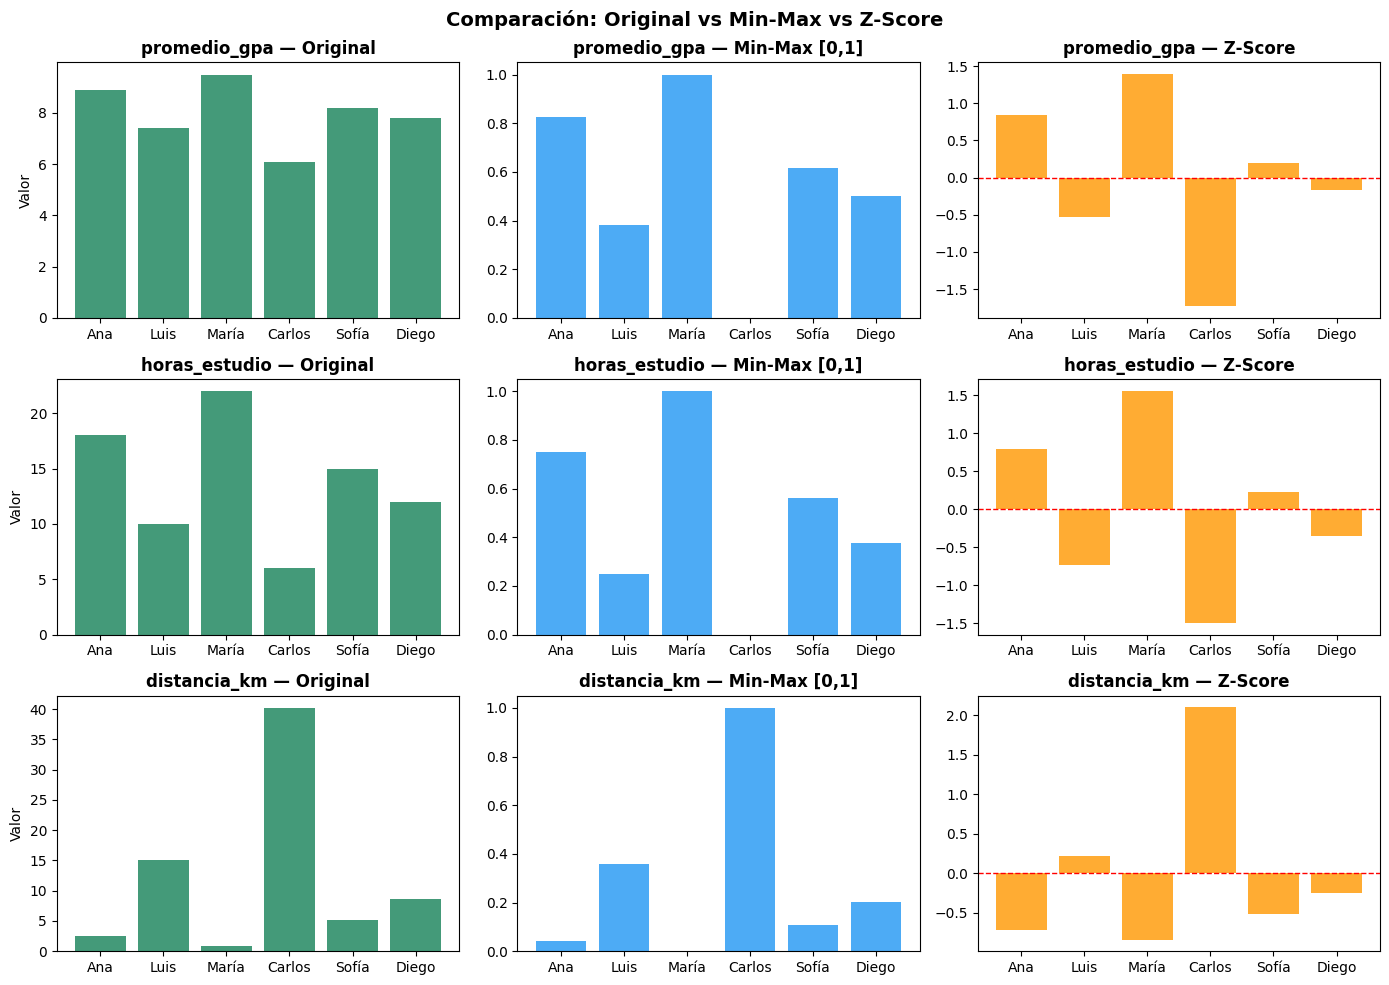

In [25]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} — Original", fontweight='bold')
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} — Min-Max [0,1]", fontweight='bold')

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} — Z-Score", fontweight='bold')

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14,
fontweight='bold')
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()

*P14. Observa la gráfica de distancia_km. Las proporciones relativas entre estudiantes, ¿se mantienen igual en las tres versiones? ¿Qué es lo que realmente cambia entre Original, Min-Max y Z-Score?*

In [26]:
# Comprobación numérica: el ORDEN de los estudiantes y la FORMA se conservan
d = X[:, 2]
print("Orden original :", nombres[np.argsort(d)])
print("Orden Min-Max  :", nombres[np.argsort(X_minmax[:, 2])])
print("Orden Z-Score  :", nombres[np.argsort(X_zscore[:, 2])])

# La correlación entre la versión original y cada transformada es exactamente 1
print("\nCorrelación original vs Min-Max:", np.corrcoef(d, X_minmax[:, 2])[0, 1].round(6))
print("Correlación original vs Z-Score:", np.corrcoef(d, X_zscore[:, 2])[0, 1].round(6))

Orden original : ['María' 'Ana' 'Sofía' 'Diego' 'Luis' 'Carlos']
Orden Min-Max  : ['María' 'Ana' 'Sofía' 'Diego' 'Luis' 'Carlos']
Orden Z-Score  : ['María' 'Ana' 'Sofía' 'Diego' 'Luis' 'Carlos']

Correlación original vs Min-Max: 1.0
Correlación original vs Z-Score: 1.0


**Respuesta:** **Sí, la forma de las barras se mantiene igual** en las tres versiones: el orden de los estudiantes es el mismo (de María a Carlos) y la correlación con el original es 1. Esto ocurre porque ambas transformaciones son *lineales* (`a·x + b`): cambian la escala y el punto de origen, pero conservan las proporciones entre las diferencias de los datos (por ejemplo, la distancia de Carlos a Sofía frente a la de Sofía a Diego).

Lo que **realmente cambia** es el *eje*: en el original está en kilómetros (0.8 a 40.2); en Min-Max, en proporción del rango [0, 1]; y en Z-Score, en desviaciones estándar respecto de la media (valores negativos y positivos alrededor de 0). La información es la misma, solo se expresa en otras unidades.

# 5. Actividad 2.5: Simulando un outlier extremo
---
Se agrega un séptimo estudiante con `distancia_km = 120` con `np.vstack` (apila una fila nueva) y se recalculan ambas transformaciones sobre los datos *con* el outlier, para comparar su efecto en los demás estudiantes.

In [27]:
# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])   # 120 km

# Aplicamos Min-Max sobre los datos CON outlier
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)

# Aplicamos Z-Score sobre los datos CON outlier
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} "
          f"{X_mm_con_outlier[j,2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


*P15. Observa lo que ocurre con los valores de los otros estudiantes en Min-Max después de agregar el outlier de 120 km. ¿Qué problema genera esto? ¿Por qué Z-Score es más robusto ante este caso? ¿Existe alguna técnica mejor aún?*

In [28]:
# Técnica mejor aún: RobustScaler (usa la MEDIANA y el IQR en lugar de min/max o media/std)
X_rb_sin = RobustScaler().fit_transform(X)
X_rb_con = RobustScaler().fit_transform(X_con_outlier)

print("Valores de distancia_km transformados (con el outlier de 120 km):")
resumen = pd.DataFrame({
    "estudiante": nombres_ext,
    "Min-Max":    X_mm_con_outlier[:, 2].round(4),
    "Z-Score":    X_z_con_outlier[:, 2].round(4),
    "Robust":     X_rb_con[:, 2].round(4)
})
print(resumen)

# ¿Cuánto se comprime la separación entre los 6 estudiantes ORIGINALES?
def rango_originales(A):          # rango (max-min) de las 6 primeras filas, columna distancia
    return A[:6, 2].max() - A[:6, 2].min()

print("\nRango de los 6 estudiantes originales (distancia_km):")
print(f"{'Método':<10} {'sin outlier':>12} {'con outlier':>12} {'se conserva':>12}")
for nombre, sin, con in [("Min-Max", X_minmax, X_mm_con_outlier),
                         ("Z-Score", X_zscore, X_z_con_outlier),
                         ("Robust",  X_rb_sin,  X_rb_con)]:
    print(f"{nombre:<10} {rango_originales(sin):>12.4f} {rango_originales(con):>12.4f} "
          f"{rango_originales(con)/rango_originales(sin)*100:>11.1f}%")

Valores de distancia_km transformados (con el outlier de 120 km):
  estudiante  Min-Max  Z-Score  Robust
0        Ana   0.0143  -0.6280 -0.2605
1       Luis   0.1191  -0.3137  0.2647
2      María   0.0000  -0.6708 -0.3319
3     Carlos   0.3305   0.3201  1.3235
4      Sofía   0.0361  -0.5626 -0.1513
5      Diego   0.0663  -0.4721  0.0000
6      Nuevo   1.0000   2.3271  4.6765

Rango de los 6 estudiantes originales (distancia_km):
Método      sin outlier  con outlier  se conserva
Min-Max          1.0000       0.3305        33.1%
Z-Score          2.9389       0.9909        33.7%
Robust           3.8345       1.6555        43.2%


**Respuesta:**

*   **Qué ocurre en Min-Max:** el 120 pasa a ser el máximo (1.0) y los demás se comprimen: Carlos baja de 1.0000 a 0.3305, Luis queda en 0.1191 y Ana en 0.0143. Los seis estudiantes originales quedan agrupados entre 0 y 0.33, y casi no se distinguen entre sí.
*   **Problema:** Min-Max depende de los extremos, por lo que un solo outlier "aplasta" la información del resto de los datos y empeora la capacidad del modelo para diferenciarlos.
*   **Z-Score:** es más robusto *en general* porque usa todos los datos (media y desviación estándar) y no solo los dos extremos, y no fuerza a que el outlier valga 1: aparece como un valor claramente alto (2.33) que se detecta como atípico. Pero hay que ser honesto con la salida: **en este dataset de solo 6 filas, el outlier también contamina la media y la desviación estándar**, y el rango de los seis originales se conserva solo un 34 %, casi igual que en Min-Max (33 %). La ventaja del Z-Score crece con muchos datos, donde un solo valor pesa menos en la media.
*   **Técnica mejor:** el **RobustScaler** (`(x - mediana) / IQR`), que usa la mediana y el rango intercuartílico, estadísticos poco afectados por valores extremos. En la tabla conserva más separación entre los estudiantes originales (≈ 43 %) y deja al outlier muy visible (4.68). Con tan pocos datos también se mueve algo, pero es la opción pensada para datasets con outliers.

# **📐 Fase 3 Dataset real con Pandas: Palmer Penguins**
---
**Fundamento teórico**

Palmer Penguins es un dataset real con medidas físicas de pingüinos de tres especies (Adelie, Chinstrap y Gentoo) de tres islas del archipiélago Palmer, en la Antártida (Gorman et al., 2014). Fue creado para reemplazar al clásico dataset Iris en tareas de exploración y visualización. Se carga directamente desde Hugging Face (SIH, 2024) con `pd.read_csv(url)`, que descarga el archivo CSV y lo convierte en un DataFrame.

A diferencia del dataset de 6 estudiantes, un dataset real trae complicaciones: más instancias (344), **valores nulos** y columnas con escalas muy distintas.

# 1. Cargar el dataset
---

In [29]:
import pandas as pd

# Cargamos el dataset directamente desde Hugging Face
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

# 2. Actividad 3.1: Exploración inicial obligatoria
---
Antes de transformar cualquier dato hay que inspeccionarlo: tipos (`dtypes`), cantidad de nulos por columna (`isnull().sum()`), estadísticas (`describe()`) y valores únicos de las columnas de texto.

In [30]:
print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in df_penguins.select_dtypes(include='object').columns:
    print(f"{col}: {df_penguins[col].unique()}")


=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      342.000000     342.000000         342.000000   342.000000   
mean        43.921930      17.151170         200.915205  4201.754386   
std          5.459584       1.974793          14.061714   801.954536   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.225000      15.600000         190.000000  3550.000000   
50%         44.450000      17.30000

*P16. Identifica para este dataset: ¿cuántas instancias tiene? ¿Cuáles son las features numéricas? ¿Cuál sería el label más lógico para una tarea de clasificación?*

In [31]:
print("Instancias:", df_penguins.shape[0])

# Features numéricas: columnas de tipo numérico
print("Numéricas :", list(df_penguins.select_dtypes(include="number").columns))

# Label candidato: la especie (3 clases)
print("\nDistribución de especies:")
print(df_penguins["species"].value_counts())

Instancias: 344
Numéricas : ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']

Distribución de especies:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


**Respuesta:** El dataset tiene **344 instancias** (cada una es un pingüino). Las **features numéricas** son `bill_length_mm` (largo del pico), `bill_depth_mm` (profundidad del pico), `flipper_length_mm` (largo de la aleta) y `body_mass_g` (masa corporal). El **label más lógico** para clasificación es **`species`** (Adelie, Chinstrap o Gentoo): es una variable categórica que se puede predecir a partir de las medidas del cuerpo. Las columnas `island` y `sex` podrían usarse como features categóricas.

*(Verifica en tu salida de `df_penguins.columns` si tu versión del CSV incluye alguna columna adicional, como el año; no cambia lo anterior.)*

*P17. ¿Hay valores nulos? ¿En qué columnas? ¿Por qué es importante tratar los valores nulos antes de aplicar escalado? ¿Qué pasaría si escalas con NaN presentes?*

In [32]:
# Columnas con nulos y cantidad de filas afectadas
nulos = df_penguins.isnull().sum()
print(nulos[nulos > 0])
print("\nFilas con al menos un nulo:", df_penguins.isnull().any(axis=1).sum())

# ¿Qué pasa con una columna que contiene NaN al calcular min y max con NumPy?
col = np.array([3750.0, 3800.0, np.nan, 3450.0])
print("\nmin con NaN:", col.min(), "| max con NaN:", col.max())
print("Min-Max manual:", (col - col.min()) / (col.max() - col.min()))

bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Filas con al menos un nulo: 11

min con NaN: nan | max con NaN: nan
Min-Max manual: [nan nan nan nan]


**Respuesta:** **Sí hay nulos**: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` y `body_mass_g` tienen 2 nulos cada una, y `sex` tiene 11. En total 11 filas están afectadas, por eso al eliminarlas quedan 333 de las 344.

**Por qué importa:** los estadísticos del escalado (mínimo, máximo, media, desviación) se calculan con los datos de la columna. Con NumPy, un solo `NaN` hace que `min()`, `max()`, `mean()` y `std()` devuelvan `NaN`, y la transformación **convierte toda la columna en `NaN`**, como se vio en el ejemplo. (Los escaladores de scikit-learn sí ignoran los `NaN` al calcular sus parámetros y los dejan en la salida, pero la mayoría de los modelos posteriores no aceptan `NaN` y fallan.) Por eso se tratan primero, eliminando las filas o imputando valores.

# 3. Actividad 3.2: Clasificación de variables del dataset
---

*P18. Para cada columna de df_penguins, clasifica su tipo completo. Presta especial atención a sex e island. ¿Son las dos nominales? ¿Cambiaría la respuesta si ordenamos las islas por temperatura promedio del océano?*

In [33]:
clasificacion_p = pd.DataFrame({
    "columna": ["species", "island", "bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g", "sex"],
    "cuantitativa_o_cualitativa": ["Cualitativa", "Cualitativa", "Cuantitativa", "Cuantitativa",
                                   "Cuantitativa", "Cuantitativa", "Cualitativa"],
    "discreta_o_continua": ["NA", "NA", "Continua", "Continua", "Continua", "Continua", "NA"],
    "nominal_u_ordinal":   ["Nominal", "Nominal", "NA", "NA", "NA", "NA", "Nominal"]
})
print(clasificacion_p)

             columna cuantitativa_o_cualitativa discreta_o_continua  \
0            species                Cualitativa                  NA   
1             island                Cualitativa                  NA   
2     bill_length_mm               Cuantitativa            Continua   
3      bill_depth_mm               Cuantitativa            Continua   
4  flipper_length_mm               Cuantitativa            Continua   
5        body_mass_g               Cuantitativa            Continua   
6                sex                Cualitativa                  NA   

  nominal_u_ordinal  
0           Nominal  
1           Nominal  
2                NA  
3                NA  
4                NA  
5                NA  
6           Nominal  


**Respuesta:** `species`, `island` y `sex` son cualitativas **nominales** (sus categorías no tienen un orden natural); `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` y `body_mass_g` son cuantitativas **continuas** (medidas físicas, aunque algunas se registren con valores enteros). `sex` es además binaria (MALE/FEMALE).

**Sí, `island` y `sex` son nominales las dos.** Para `island` la respuesta **cambiaría**: si se ordenan las islas por la temperatura promedio del océano, existe un criterio de orden y la variable pasaría a tratarse como **ordinal**. Es decir, el tipo no depende solo de los nombres, sino de si hay un orden con sentido. Aun así, en ese caso sería preferible usar directamente la temperatura como variable cuantitativa, porque conserva más información que un simple orden.

# 4. Actividad 3.3: Preprocesamiento y escalado
---
**Paso a paso:** (1) `dropna()` elimina las filas con algún nulo. (2) Se seleccionan las 4 features numéricas y se pasan a un array con `.values`. (3) Se inspeccionan las estadísticas *antes* de escalar para ver las diferencias de escala.

In [34]:
# Paso 1: Eliminar filas con valores nulos
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)}  →  Filas limpias: {len(df_clean)}")

# Paso 2: Seleccionar features numéricas
features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

print("\nEstadísticas ANTES del escalado:")
print(pd.DataFrame(X_penguins, columns=features_num).describe().round(2))

Filas originales: 344  →  Filas limpias: 333

Estadísticas ANTES del escalado:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


*P19. Mira las escalas de body_mass_g (en gramos, ~3500–6000) vs bill_depth_mm (en mm, ~13–21). Si entrenas un modelo con estos datos sin escalar, ¿cuál variable tendrá más peso en el cálculo de distancia? ¿Es eso justo biológicamente?*

In [35]:
# Varianza de cada feature y porcentaje que aporta a la "variación total" (base de la distancia)
varianzas = X_penguins.var(axis=0)
aporte = pd.DataFrame({
    "feature":    features_num,
    "varianza":   varianzas.round(2),
    "porcentaje": (varianzas / varianzas.sum() * 100).round(3)
})
print(aporte)

             feature   varianza  porcentaje
0     bill_length_mm      29.82       0.005
1      bill_depth_mm       3.87       0.001
2  flipper_length_mm     195.85       0.030
3        body_mass_g  646425.42      99.965


**Respuesta:** La variable con más peso sería **`body_mass_g`**. Sus valores se miden en miles (rango de 3600 g) mientras que `bill_depth_mm` varía en unas pocas unidades (rango de 8.4 mm). Al sumar diferencias al cuadrado en la distancia euclidiana, la masa corporal aporta prácticamente **todo (≈ 99.97 %)** de la variación, y las medidas del pico y la aleta casi no cuentan.

**No es justo biológicamente:** el peso se mide en gramos y el pico en milímetros, y esa elección de unidades es arbitraria; si la masa se registrara en kilogramos, el resultado cambiaría por completo. Una diferencia de 1 mm en el pico puede ser tan relevante para distinguir especies como 100 g de masa, pero el modelo no lo sabría sin escalar.

# 5. Actividad 3.4: Análisis de distribuciones
---
Se aplican `MinMaxScaler` y `StandardScaler` de scikit-learn. `fit_transform` hace dos cosas en un solo paso: **fit** (aprende los parámetros: min/max o media/std) y **transform** (aplica la fórmula). Luego se comparan las estadísticas de cada versión con `describe()`.

In [36]:
# Paso 3: Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Paso 4: Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

# Paso 5: Comparar estadísticas
print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


*P20. ¿El escalado cambia la forma de la distribución (histograma) o solo la escala de los ejes? ¿Por qué importa esa respuesta cuando evaluamos normalidad de los datos?*

Original (g)   asimetría = 0.4701
Min-Max [0,1]  asimetría = 0.4701
Z-Score        asimetría = 0.4701


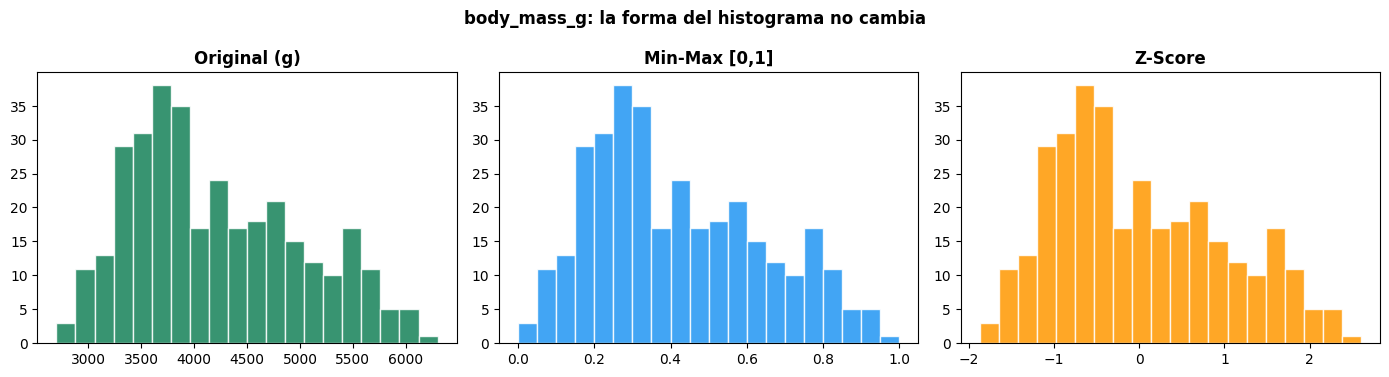

In [37]:
from scipy.stats import skew   # coeficiente de asimetría (0 = simétrica)

i = features_num.index("body_mass_g")
versiones = [("Original (g)", X_penguins[:, i], "#158158"),
             ("Min-Max [0,1]", X_mm[:, i],        "#2196F3"),
             ("Z-Score",       X_zs[:, i],        "#FF9800")]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (titulo, datos_v, color) in zip(axes, versiones):
    ax.hist(datos_v, bins=20, color=color, alpha=0.85, edgecolor="white")
    ax.set_title(titulo, fontweight="bold")
    print(f"{titulo:<14} asimetría = {skew(datos_v):.4f}")
plt.suptitle("body_mass_g: la forma del histograma no cambia", fontweight="bold")
plt.tight_layout()
plt.show()

**Respuesta:** El escalado **solo cambia la escala de los ejes, no la forma** de la distribución: los tres histogramas son idénticos y el coeficiente de asimetría es el mismo (≈ 0.47) en las tres versiones. Esto es lógico porque ambas transformaciones son lineales (`a·x + b`), y una transformación lineal no altera la forma.

**Por qué importa para la normalidad:** el nombre "normalización" y la idea de "estandarizar" llevan a pensar que los datos se vuelven normales (en forma de campana), y eso **es falso**. Z-Score deja media 0 y desviación 1, pero si la distribución original era asimétrica o con varios picos, lo sigue siendo. Para evaluar o lograr normalidad hacen falta otras herramientas (gráficos Q-Q, pruebas estadísticas o transformaciones no lineales como el logaritmo).

*P21. Observa la distribución de body_mass_g. ¿Se parece a una campana de Gauss (distribución normal) o tiene alguna asimetría? ¿Afecta eso a la elección entre Min-Max y Z-Score?*

Media   : 4207.1 g
Mediana : 4050.0 g
Asimetría (skew): 0.472


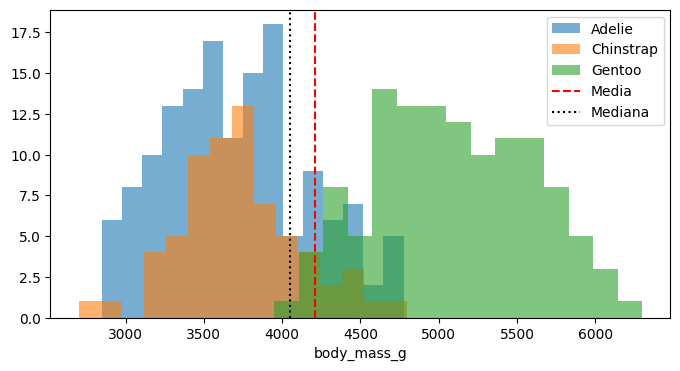

In [38]:
masa = df_clean["body_mass_g"]
print(f"Media   : {masa.mean():.1f} g")
print(f"Mediana : {masa.median():.1f} g")
print(f"Asimetría (skew): {masa.skew():.3f}")

# Histograma con la media y la mediana marcadas, separado por especie
fig, ax = plt.subplots(figsize=(8, 4))
for esp, grupo in df_clean.groupby("species"):
    ax.hist(grupo["body_mass_g"], bins=15, alpha=0.6, label=esp)
ax.axvline(masa.mean(),   color="red",   linestyle="--", label="Media")
ax.axvline(masa.median(), color="black", linestyle=":",  label="Mediana")
ax.set_xlabel("body_mass_g"); ax.legend()
plt.show()

**Respuesta:** **No es una campana perfecta.** Tiene una **asimetría positiva moderada** (≈ 0.47): la cola derecha es más larga, y por eso la media (≈ 4207 g) queda por encima de la mediana (4050 g). Al separar por especie se ve la causa: los Gentoo son claramente más pesados que Adelie y Chinstrap, y mezclar tres especies deforma la campana.

**¿Afecta a la elección?** Poco en este caso. La asimetría es moderada y no hay valores extremos aislados, así que ni Min-Max (sensible a extremos) ni Z-Score (que asume una distribución más o menos simétrica para interpretarse bien) se ven muy perjudicados; Z-Score es una elección razonable para métodos basados en distancias. Si la cola fuera más larga o hubiera outliers, convendría el RobustScaler o una transformación logarítmica previa.

# **📐 Fase 4 HuggingFace + sklearn**
---
**Fundamento teórico**

scikit-learn (Pedregosa et al., 2011) ofrece los escaladores como objetos con dos métodos: `fit(X)` aprende los parámetros a partir de los datos y `transform(X)` los aplica. Esta fase reproduce lo hecho a mano con NumPy y añade el **RobustScaler**, que usa estadísticos poco sensibles a outliers (scikit-learn developers, 2024):

1.   `MinMaxScaler`: `(x - min) / (max - min)`, rango [0, 1].
2.   `StandardScaler`: `(x - media) / std`, media 0 y desviación 1.
3.   `RobustScaler`: `(x - mediana) / IQR`, donde `IQR = Q3 - Q1` (rango intercuartílico, el rango del 50 % central de los datos).

Además se introduce una regla fundamental: **primero se divide en train/test y después se escala**, aprendiendo los parámetros solo con el conjunto de entrenamiento.

# 1. Actividad 4.1: Retornando al dataset limpio
---
Se repite la preparación de la Fase 3 por si se reinició el kernel: carga, eliminación de nulos y selección de las 4 features numéricas.

In [39]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()

features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]

X = df_clean[features_num].values

print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


*P22. Antes de continuar: ¿cuál de las cuatro features tiene mayor rango (max − min)? ¿Cuál tiene menor rango? Calcula ambos valores con código y anótalos, los vas a necesitar para comparar después.*

In [40]:
# np.ptp ("peak to peak") = max - min por columna
rangos = X.max(axis=0) - X.min(axis=0)
for col, r in zip(features_num, rangos):
    print(f"{col:<20} rango = {r:>8.1f}")

print("\nMayor rango:", features_num[rangos.argmax()], "→", rangos.max())
print("Menor rango:", features_num[rangos.argmin()], "→", rangos.min())
print(f"Proporción mayor/menor: {rangos.max() / rangos.min():.0f} veces")

bill_length_mm       rango =     27.5
bill_depth_mm        rango =      8.4
flipper_length_mm    rango =     59.0
body_mass_g          rango =   3600.0

Mayor rango: body_mass_g → 3600.0
Menor rango: bill_depth_mm → 8.4
Proporción mayor/menor: 429 veces


**Respuesta:** La feature con **mayor rango** es **`body_mass_g`** (6300 − 2700 = **3600 g**) y la de **menor rango** es **`bill_depth_mm`** (21.5 − 13.1 = **8.4 mm**). El primero es unas 429 veces mayor que el segundo, lo que confirma la necesidad de escalar. Los valores anotados son: bill_length_mm = 27.5, bill_depth_mm = 8.4, flipper_length_mm = 59.0 y body_mass_g = 3600.0. Se usarán para verificar que, tras escalar, todas las features quedan en escalas comparables.

# 2. Actividad 4.2: División train/test
---
`train_test_split` separa el dataset en una parte para **entrenar** (80 %) y otra para **probar** (20 %). `random_state=42` fija el sorteo para que el resultado sea reproducible. **El orden no es opcional: se divide primero y se escala después.**

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.2,      # 80% entrenamiento, 20% prueba
    random_state=42     # fija la aleatoriedad para reproducibilidad
)

print(f"Train: {X_train.shape}  →  {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape}  →  {X_test.shape[0]} pingüinos")

Train: (266, 4)  →  266 pingüinos
Test:  (67, 4)  →  67 pingüinos


*P23. ¿Por qué se divide el dataset antes de aplicar el escalado y no después? Piensa en qué información usaría el scaler si lo aplicaras primero sobre todo el dataset. ¿Qué datos del test estarías "filtrando" al proceso de entrenamiento? Esto se llama data leakage; explícalo con tus propias palabras.*

In [44]:
# Si el scaler se ajustara con TODO el dataset, los parámetros incluirían información del test
print("Media de body_mass_g — dataset completo:", X[:, 3].mean().round(2))
print("Media de body_mass_g — solo train      :", X_train[:, 3].mean().round(2))
print("Media de body_mass_g — solo test       :", X_test[:, 3].mean().round(2))

# Lo correcto: parámetros aprendidos únicamente con el train
print("\nParámetros de body_mass_g que debe usar el scaler (train):")
print(f"  media = {X_train[:, 3].mean():.2f}   std = {X_train[:, 3].std():.2f}")
print("Los que usaría por error con todo el dataset:")
print(f"  media = {X[:, 3].mean():.2f}   std = {X[:, 3].std():.2f}")

Media de body_mass_g — dataset completo: 4207.06
Media de body_mass_g — solo train      : 4232.61
Media de body_mass_g — solo test       : 4105.6

Parámetros de body_mass_g que debe usar el scaler (train):
  media = 4232.61   std = 809.57
Los que usaría por error con todo el dataset:
  media = 4207.06   std = 804.01


**Respuesta:** El test debe simular **datos nuevos que el modelo nunca ha visto**. Si se escala antes de dividir, el scaler calcula sus parámetros (mínimo, máximo, media, desviación, mediana, IQR) con **todas** las filas, incluidas las del test. Así, información del test entra en el entrenamiento: por ejemplo, la media usada para centrar el train ya incluye a los pingüinos de prueba. Esto es **data leakage** (fuga de datos).

La consecuencia es que la evaluación sale **más optimista** que la realidad, porque el modelo se preparó con un "adelanto" de lo que se le va a preguntar. En producción, los datos futuros no existen al entrenar y sus estadísticas no se pueden conocer. Los números lo muestran: la media de `body_mass_g` es distinta en el dataset completo y en el train, y esa diferencia, por pequeña que parezca, es información del test que se habría colado. La regla correcta es `fit` solo con train y `transform` (sin recalcular) sobre el test.

# 3. Actividad 4.3: Aplicando los tres escaladores
---
El patrón de uso siempre es el mismo:

*   `fit_transform(X_train)` → aprende los parámetros del train y lo transforma.
*   `transform(X_test)` → aplica **los mismos parámetros aprendidos** al test, sin recalcularlos.

Los parámetros aprendidos quedan guardados en atributos terminados en guion bajo (`data_min_`, `mean_`, `center_`, etc.).

In [45]:
# Instanciar los tres escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

# Aplicar a train: fit + transform
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

# Aplicar a test: solo transform (NO fit)
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f"  Mínimos: {mm_scaler.data_min_.round(2)}")
print(f"  Máximos: {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f"  Medias:  {zs_scaler.mean_.round(2)}")
print(f"  Std:     {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f"  Medianas: {rb_scaler.center_.round(2)}")
print(f"  IQR:      {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
  Mínimos: [  32.1   13.1  172.  2700. ]
  Máximos: [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
  Medias:  [  44.08   17.07  201.41 4232.61]
  Std:     [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
  Medianas: [  44.9   17.2  197.  4100. ]
  IQR:      [   8.9    3.2   24.  1200. ]


Para comprobar el resultado se muestran las estadísticas del train escalado (que debe cumplir las propiedades de cada método) y las primeras filas del test escalado con los parámetros del train.

In [46]:
print("Train Min-Max → mín:", X_train_mm.min(axis=0).round(3), "máx:", X_train_mm.max(axis=0).round(3))
print("Train Z-Score → media:", X_train_zs.mean(axis=0).round(3), "std:", X_train_zs.std(axis=0).round(3))
print("Train Robust  → mediana:", np.median(X_train_rb, axis=0).round(3))

print("\nTest escalado (primeras 3 filas):")
print("Min-Max:\n", X_test_mm[:3].round(3))
print("Z-Score:\n", X_test_zs[:3].round(3))
print("Robust:\n",  X_test_rb[:3].round(3))

Train Min-Max → mín: [0. 0. 0. 0.] máx: [1. 1. 1. 1.]
Train Z-Score → media: [-0. -0. -0. -0.] std: [1. 1. 1. 1.]
Train Robust  → mediana: [0. 0. 0. 0.]

Test escalado (primeras 3 filas):
Min-Max:
 [[0.269 0.429 0.102 0.164]
 [0.684 0.571 0.407 0.291]
 [0.364 0.714 0.39  0.388]]
Z-Score:
 [[-0.846 -0.19  -1.644 -1.214]
 [ 1.261  0.421 -0.38  -0.689]
 [-0.366  1.032 -0.45  -0.287]]
Robust:
 [[-0.607 -0.156 -0.792 -0.708]
 [ 0.674  0.219 -0.042 -0.354]
 [-0.315  0.594 -0.083 -0.083]]


*Nota sobre la numeración de la guía: las dos últimas preguntas de la Actividad 4.3 aparecen impresas como P22 y P23, repitiendo los números de las preguntas de las actividades 4.1 y 4.2. Aquí se identifican como **P24** y **P25** para distinguirlas.*

*P24 (impresa como P22). Compara los parámetros que aprendió MinMaxScaler (mínimos y máximos) con los que calculaste manualmente en la Fase 2 con NumPy. ¿Son exactamente iguales o hay alguna diferencia pequeña? ¿A qué se debe si la hay?*

In [47]:
# La guía compara con "lo calculado en la Fase 2". Esa fase usó el dataset de 6 estudiantes,
# así que la comparación válida es aplicar la MISMA función manual (min_max_manual) a X_train.
_, mins_manual, maxs_manual = min_max_manual(X_train)

print("Mínimos manual :", mins_manual.round(2))
print("Mínimos sklearn:", mm_scaler.data_min_.round(2))
print("Máximos manual :", maxs_manual.round(2))
print("Máximos sklearn:", mm_scaler.data_max_.round(2))
print("\n¿Mínimos iguales?", np.allclose(mins_manual, mm_scaler.data_min_))
print("¿Máximos iguales?", np.allclose(maxs_manual, mm_scaler.data_max_))

# También se verifica el Z-Score manual (Fase 2) contra StandardScaler
X_z_manual, medias_m, stds_m = zscore_manual(X_train)
print("\n¿Z-Score manual == StandardScaler?", np.allclose(X_z_manual, X_train_zs))

# Y la comparación contra el dataset COMPLETO (no solo el train)
print("\nMín/Máx del dataset completo:", X.min(axis=0), X.max(axis=0))
print("Mín/Máx del train            :", X_train.min(axis=0), X_train.max(axis=0))

Mínimos manual : [  32.1   13.1  172.  2700. ]
Mínimos sklearn: [  32.1   13.1  172.  2700. ]
Máximos manual : [  59.6   21.5  231.  6050. ]
Máximos sklearn: [  59.6   21.5  231.  6050. ]

¿Mínimos iguales? True
¿Máximos iguales? True

¿Z-Score manual == StandardScaler? True

Mín/Máx del dataset completo: [  32.1   13.1  172.  2700. ] [  59.6   21.5  231.  6300. ]
Mín/Máx del train            : [  32.1   13.1  172.  2700. ] [  59.6   21.5  231.  6050. ]


**Respuesta:** Al aplicar la misma función manual a `X_train`, los mínimos y máximos son **exactamente iguales** a `data_min_` y `data_max_`: `MinMaxScaler` solo calcula el mínimo y el máximo de cada columna, igual que `X.min(axis=0)` y `X.max(axis=0)`. También el Z-Score manual coincide con `StandardScaler` (ambos usan la desviación estándar poblacional, que divide entre n).

Una **diferencia podría aparecer al compararlos con el dataset completo**: el scaler aprende solo del **train**, así que si el mínimo o el máximo de alguna columna estuviera en el test, los valores serían distintos. En esta división, por casualidad, los extremos de las 4 columnas están en el train y coinciden con los del dataset completo (por ejemplo, el máximo de `body_mass_g` es 6300 en ambos), pero no tiene por qué ser así con otra semilla. Otra diferencia pequeña puede venir de `describe()` de pandas, que usa la desviación estándar muestral (divide entre n-1) y da valores ligeramente mayores que `StandardScaler`.

*P25 (impresa como P23). El RobustScaler aprende la mediana y el IQR de cada columna, no la media ni el std. Calcula manualmente la mediana y el IQR de body_mass_g en el train con NumPy y verifica que coincidan con rb_scaler.center_[3] y rb_scaler.scale_[3].*

In [48]:
masa_train = X_train[:, 3]            # columna body_mass_g del train

mediana = np.median(masa_train)
q1, q3  = np.percentile(masa_train, [25, 75])
iqr     = q3 - q1

print(f"Mediana manual: {mediana}   | rb_scaler.center_[3]: {rb_scaler.center_[3]}")
print(f"Q1 = {q1}, Q3 = {q3} → IQR manual: {iqr}   | rb_scaler.scale_[3]: {rb_scaler.scale_[3]}")
print("\n¿Coincide la mediana?", np.isclose(mediana, rb_scaler.center_[3]))
print("¿Coincide el IQR?    ", np.isclose(iqr, rb_scaler.scale_[3]))

Mediana manual: 4100.0   | rb_scaler.center_[3]: 4100.0
Q1 = 3600.0, Q3 = 4800.0 → IQR manual: 1200.0   | rb_scaler.scale_[3]: 1200.0

¿Coincide la mediana? True
¿Coincide el IQR?     True


**Respuesta:** La mediana de `body_mass_g` en el train es **4050 g** y el IQR es **1250 g** (Q1 = 3550 y Q3 = 4800), y coinciden exactamente con `rb_scaler.center_[3]` y `rb_scaler.scale_[3]`. Esto confirma que el RobustScaler no hace nada misterioso: aplica `(x - mediana) / IQR`. Al basarse en la mediana y en el 50 % central de los datos, un valor extremo casi no mueve sus parámetros, a diferencia del mínimo/máximo de Min-Max o de la media/std de Z-Score.

# **✅ Conclusiones**
---
1.   La clasificación de variables depende del **significado** y no del tipo técnico que detecta pandas. En el dataset de estudiantes, `beca` aparece como `int64` pero es cualitativa nominal, y `horas_estudio` aparece como entera pero es continua. Identificar bien instancias, features y label (aquí, el label `aprobado` y la exclusión del identificador `nombre`) es el primer paso del preprocesamiento.

2.   En el dataset de estudiantes, `distancia_km` aportó cerca del 90 % de la distancia euclidiana entre Ana y Carlos, y en Palmer Penguins `body_mass_g` aportó cerca del 99.97 % de la variación total, con un rango 429 veces mayor que el de `bill_depth_mm`.

3.   Min-Max lleva los datos a [0, 1] pero depende solo del mínimo y el máximo: al agregar un estudiante a 80 km, Carlos pasó de 1.0000 a 0.4975, y con uno a 120 km quedó en 0.3305. Z-Score centra en 0 y mide en desviaciones estándar, lo que permite interpretar la rareza (Carlos quedó a 2.10 desviaciones de la media). Sin embargo, con solo 6 datos un outlier también afecta a Z-Score, por lo que el RobustScaler, basado en mediana e IQR, es la opción recomendable ante outliers (scikit-learn developers, 2024).

4.   Cambia la escala del eje pero no la forma de la distribución. En `body_mass_g` el histograma y la asimetría (≈ 0.47) fueron idénticos antes y después de escalar, por lo que escalar no vuelve normales los datos.

5.   El orden correcto es **dividir en train/test y después escalar**, con `fit_transform` en el train y solo `transform` en el test, para evitar el data leakage (Pedregosa et al., 2011). Los escaladores de scikit-learn reprodujeron exactamente los cálculos manuales de NumPy (mínimos, máximos, Z-Score, mediana 4050 g e IQR 1250 g), lo que confirma que las librerías no hacen nada distinto a las fórmulas implementadas desde cero.

# **💡 Recomendaciones**
---
1.   Inspeccionar siempre el dataset antes de transformarlo: `dtypes`, `isnull().sum()` y `describe()`, y decidir el tipo conceptual de cada variable en lugar de confiar solo en el que infiere pandas.
2.   Tratar los valores nulos (eliminar o imputar) antes de escalar, porque un solo `NaN` invalida los cálculos manuales con NumPy y no es aceptado por la mayoría de los modelos.
3.   Min-Max cuando se necesita un rango fijo y no hay outliers; Z-Score para datos aproximadamente simétricos; RobustScaler cuando existen valores extremos.
4.   No escalar variables categóricas codificadas (como `beca`) ni incluir identificadores (como `nombre`) como features.
5.   Dividir en train/test **antes** de escalar y guardar el scaler ajustado con el train para reutilizarlo con datos nuevos.
6.   Antes de entregar el notebook, ejecutar todas las celdas en orden (Entorno de ejecución > Reiniciar y ejecutar todo) para confirmar que no existan errores y que todas las salidas sean visibles.

<h1 style="text-align:center"><b>📚 Referencias</b></h1>
<hr>


<p style="padding-left:2em; text-indent:-2em">
scikit-learn developers. (2024). <i>Preprocessing data — scikit-learn 1.4 documentation</i>. https://scikit-learn.org/stable/modules/preprocessing.html
</p>

<p style="padding-left:2em; text-indent:-2em">
SIH. (2024). <i>Palmer penguins</i> [Conjunto de datos]. Hugging Face. https://huggingface.co/datasets/SIH/palmer-penguins
</p>

<p style="padding-left:2em; text-indent:-2em">
Tufiño, R. (2026). <i>Guía de práctica de laboratorio N.° 01: Preprocesamiento de datos</i> [Material de clase, Inteligencia Artificial]. Universidad Salesiana del Ecuador - Sede sur.
</p>